# Instance segmentation ruangan

## 1. Install

In [1]:
import subprocess
import sys
from importlib.metadata import version

gpu_stack = [f"{name}=={version(name)}" for name in ("torch", "torchvision", "numpy")]
packages = ["ultralytics==8.4.218", "rfdetr[train]==1.12.1", "pycocotools", "plotly", "ipywidgets"]
watched = ("torch", "torchvision", "numpy", "ultralytics", "rfdetr", "transformers", "pandas", "ipywidgets")
loaded = {name: version(name) for name in watched if name in sys.modules}

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "-q", *gpu_stack, *packages],
    check=True,
)
changed = [name for name, previous in loaded.items() if version(name) != previous]
if changed:
    raise RuntimeError(f"Restart Session lalu jalankan dari awal. Paket yang berubah: {', '.join(changed)}.")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Konfigurasi dan path

In [2]:
from collections import Counter
from datetime import datetime
from pathlib import Path
import gc
import hashlib
import json
import os
import random
import time

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils
from rfdetr import RFDETR, RFDETRSegNano
from rfdetr.training import RFDETRModelModule
from torchvision.ops import nms
from ultralytics import YOLO, settings
from ultralytics.data.converter import merge_multi_segment
from ultralytics.utils.ops import scale_masks
import ipywidgets as widgets
import plotly.express as px

TRAIN_DIR = Path(
    "/kaggle/input/datasets/nazhifberlian/panoptic-indoor-segmentation-v5i-coco-segmentation/panoptic-indoor-segmentation.v5i.coco-segmentation/train"
)
VALID_DIR = Path(
    "/kaggle/input/datasets/nazhifberlian/panoptic-indoor-segmentation-v5i-coco-segmentation/panoptic-indoor-segmentation.v5i.coco-segmentation/valid"
)
TEST_ROOT = Path("/kaggle/input/datasets/nazhifberlian/40-photos-data-test/test")
own_json = TEST_ROOT / "_annotations.coco.json"

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT = Path("/kaggle/working") / f"instance_results_{RUN_ID}"
OUT.mkdir(parents=True, exist_ok=True)

YOLO_EPOCHS = 100
RF_EPOCHS = 60
YOLO_BATCH = 4
RF_BATCH = 2
IMAGE_SIZE = 960
EVAL_MAX_SIDE = 960
MAX_DETECTIONS = 1000
NUM_WORKERS = min(2, os.cpu_count() or 1)
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
cv2.setNumThreads(0)
if not torch.cuda.is_available():
    raise RuntimeError("Aktifkan GPU di Kaggle Settings lalu jalankan ulang.")

with torch.inference_mode():
    boxes = torch.tensor([[0., 0., 4., 4.]], device="cuda")
    assert nms(boxes, boxes.new_ones(1), 0.5).tolist() == [0]
    mask = np.ones((4, 4), dtype=np.uint8, order="F")
    assert mask_utils.area(mask_utils.encode(mask)) == 16
    del boxes, mask
assert (TRAIN_DIR / "_annotations.coco.json").is_file(), TRAIN_DIR
assert (VALID_DIR / "_annotations.coco.json").is_file(), VALID_DIR
assert own_json.is_file(), own_json


def release_memory():
    gc.collect()
    torch.cuda.empty_cache()


versions = {
    name: version(name)
    for name in (
        "torch", "torchvision", "numpy", "ultralytics", "rfdetr", "pytorch-lightning",
        "transformers", "supervision", "pycocotools", "ipywidgets", "plotly",
    )
}
versions.update(python=sys.version.split()[0], cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0))
(OUT / "library_versions.json").write_text(json.dumps(versions, indent=2))
print("Runtime:", versions["python"], "|", versions["gpu"], "| CUDA", versions["cuda"])
print("Train:", TRAIN_DIR)
print("Valid:", VALID_DIR)
print("Test:", TEST_ROOT)
print("Output:", OUT)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Runtime: 3.13.16 | Tesla T4 | CUDA 13.0
Train: /kaggle/input/datasets/nazhifberlian/panoptic-indoor-segmentation-v5i-coco-segmentation/panoptic-indoor-segmentation.v5i.coco-segmentation/train
Valid: /kaggle/input/datasets/nazhifberlian/panoptic-indoor-segmentation-v5i-coco-segmentation/panoptic-indoor-segmentation.v5i.coco-segmentation/valid
Test: /kaggle/input/datasets/nazhifberlian/40-photos-data-test/test
Output: /kaggle/working/instance_results_20261124_235409


## 3. Periksa dataset dan kelas

In [3]:
from pycocotools.coco import COCO

prepared_root = OUT / "prepared_coco"
excluded_images = []
for split, source in {"train": TRAIN_DIR, "valid": VALID_DIR}.items():
    target = prepared_root / split
    target.mkdir(parents=True, exist_ok=True)
    document = json.loads((source / "_annotations.coco.json").read_text())
    kept_images = []
    for info in document["images"]:
        path = source / info["file_name"]
        with Image.open(path) as image:
            orientation = image.getexif().get(274, 1)
            corrected = ImageOps.exif_transpose(image) if orientation != 1 else image
            expected = (info["width"], info["height"])
            if corrected.size != expected:
                excluded_images.append(
                    {
                        "split": split,
                        "file": info["file_name"],
                        "actual_size": str(corrected.size),
                        "annotation_size": str(expected),
                    }
                )
                continue
            destination = target / info["file_name"]
            destination.parent.mkdir(parents=True, exist_ok=True)
            if orientation != 1:
                corrected.convert("RGB").save(destination)
            elif not destination.exists():
                destination.symlink_to(path)
        kept_images.append(info)
    kept_ids = {info["id"] for info in kept_images}
    document["images"] = kept_images
    document["annotations"] = [
        ann for ann in document["annotations"] if ann["image_id"] in kept_ids
    ]
    annotation_index = COCO()
    annotation_index.dataset = document
    annotation_index.createIndex()
    for annotation in document["annotations"]:
        encoded = annotation_index.annToRLE(annotation)
        annotation["area"] = float(mask_utils.area(encoded))
        annotation["bbox"] = mask_utils.toBbox(encoded).tolist()
    del annotation_index
    assert kept_images, f"Split {split} kosong setelah pemeriksaan"
    (target / "_annotations.coco.json").write_text(json.dumps(document))
excluded = pd.DataFrame(
    excluded_images, columns=["split", "file", "actual_size", "annotation_size"]
)
excluded.to_csv(OUT / "excluded_dimension_mismatches.csv", index=False)
display(excluded)
TRAIN_ROOT = prepared_root
del document, kept_images, kept_ids


creating index...
index created!
creating index...
index created!


,split,file,actual_size,annotation_size
0,train,182169107_jpg.rf.c9b1bbecf1474a5b36a6df197c30d...,"(480, 640)","(640, 480)"
1,train,182169121_jpg.rf.eb0ccb71d0ea38adf1e38bf9c02a4...,"(480, 640)","(640, 480)"
2,valid,182169109_jpg.rf.0531e60eb6e404d9633ed0c23a381...,"(480, 640)","(640, 480)"
3,valid,182169108_jpg.rf.205d9f1ed8f888006b8f97fc29eb8...,"(480, 640)","(640, 480)"


In [4]:
def coco_path(root, split):
    return root / split / "_annotations.coco.json"


for split in ("train", "valid"):
    p = coco_path(TRAIN_ROOT, split)
    assert p.is_file(), f"Tidak ditemukan: {p}"
    d = json.loads(p.read_text())
    print(f'Panoptic {split}: {len(d["images"])} gambar, {len(d["annotations"])} anotasi')

own_json = TEST_ROOT / "_annotations.coco.json"
assert own_json.is_file(), f"Tidak ditemukan: {own_json}"
own_doc = json.loads(own_json.read_text())
assert (
    len(own_doc["images"]) == 40
), f'Test pribadi harus 40 gambar, ditemukan {len(own_doc["images"])}'
print(f'Test pribadi: {len(own_doc["images"])} gambar, {len(own_doc["annotations"])} anotasi')

train_doc = json.loads(coco_path(TRAIN_ROOT, "train").read_text())
TRAIN_CATEGORIES = sorted(train_doc["categories"], key=lambda x: x["id"])
TRAIN_NAMES = [c["name"] for c in TRAIN_CATEGORIES if c["id"] != 0]
NAME_TO_YOLO = {name: i for i, name in enumerate(TRAIN_NAMES)}
TRAIN_NAME_TO_ID = {c["name"]: c["id"] for c in TRAIN_CATEGORIES}
own_cat_names = {c["id"]: c["name"] for c in own_doc["categories"]}
unknown = sorted(
    {own_cat_names[a["category_id"]] for a in own_doc["annotations"]} - set(TRAIN_NAMES)
)
assert (
    not unknown
), f"Kelas test tidak ada di train: {unknown}. Perbaiki label Roboflow dan ekspor ulang."
assert all(a["category_id"] != 0 for a in train_doc["annotations"])
print("Kelas train yang dipakai:", len(TRAIN_NAMES))


Panoptic train: 395 gambar, 4470 anotasi
Panoptic valid: 164 gambar, 2002 anotasi
Test pribadi: 40 gambar, 3739 anotasi
Kelas train yang dipakai: 74


### Audit data sebelum training

Mask, dimensi gambar, kelas, dan duplikat diperiksa sebelum GPU digunakan. Perbaiki kegagalan audit pada dataset sumber. Jumlah contoh per kelas tersimpan untuk analisis hasil.

In [5]:
from collections import Counter
import hashlib
from PIL import Image
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils


def audit_split(folder, split):
    coco = COCO(str(folder / "_annotations.coco.json"))
    doc = coco.dataset
    for field in ("images", "annotations", "categories"):
        ids = [item["id"] for item in doc[field]]
        assert len(ids) == len(set(ids)), f"ID duplikat pada {split}/{field}"
    names = {item["id"]: item["name"] for item in doc["categories"]}
    assert len(names.values()) == len(set(names.values())), "Nama kelas duplikat"
    counts = Counter()
    fingerprints = set()
    image_counts = Counter(annotation["image_id"] for annotation in doc["annotations"])
    profile_rows = []
    for info in doc["images"]:
        path = folder / info["file_name"]
        with Image.open(path) as image:
            assert image.size == (info["width"], info["height"]), path
            pixels = image.convert("RGB")
            hasher = hashlib.sha256(str(pixels.size).encode())
            hasher.update(pixels.tobytes())
            digest = hasher.hexdigest()
            pixels.close()
        fingerprints.add(digest)
    for ann in doc["annotations"]:
        assert ann["image_id"] in coco.imgs, ann["id"]
        assert ann["category_id"] in names, ann["id"]
        name = names[ann["category_id"]]
        assert name in NAME_TO_YOLO, f"Kelas tidak dikenali: {name}"
        rle = coco.annToRLE(ann)
        assert mask_utils.area(rle) > 0, f"Mask kosong: {split}/{ann['id']}"
        info = coco.imgs[ann["image_id"]]
        if isinstance(ann["segmentation"], list):
            for polygon in ann["segmentation"]:
                points = np.asarray(polygon).reshape(-1, 2)
                assert len(points) >= 3 and np.isfinite(points).all(), ann["id"]
                assert (points >= 0).all(), ann["id"]
                assert (points[:, 0] <= info["width"]).all(), ann["id"]
                assert (points[:, 1] <= info["height"]).all(), ann["id"]
        counts[name] += 1
        scale = min(1.0, IMAGE_SIZE / max(info["width"], info["height"]))
        area = float(mask_utils.area(rle))
        profile_rows.append(
            {
                "split": split,
                "image_id": ann["image_id"],
                "annotation_id": ann["id"],
                "class": name,
                "mask_area": area,
                "estimated_area_at_input": area * scale * scale,
                "instances_in_image": image_counts[ann["image_id"]],
            }
        )
    pd.DataFrame(profile_rows).to_csv(OUT / f"{split}_object_profile.csv", index=False)
    values = [image_counts[info["id"]] for info in doc["images"]]
    print(split, "median/max instances", float(np.median(values)), max(values))
    summary = {
        "Split": split,
        "Foto": len(values),
        "Instance": sum(values),
        "Kelas aktif": len(counts),
        "Median objek/foto": np.median(values),
        "Maksimum objek/foto": max(values),
        "Mask <1024 px² pada batas 960 (%)": round(
            100 * np.mean([row["estimated_area_at_input"] < 1024 for row in profile_rows]), 1
        ),
    }
    return counts, fingerprints, summary


train_counts, train_hashes, train_summary = audit_split(TRAIN_ROOT / "train", "train")
valid_counts, valid_hashes, valid_summary = audit_split(TRAIN_ROOT / "valid", "valid")
test_counts, test_hashes, test_summary = audit_split(TEST_ROOT, "test")
assert not train_hashes & valid_hashes, "Gambar identik ditemukan pada train dan valid"
assert not (train_hashes | valid_hashes) & test_hashes, "Gambar test ditemukan pada train/valid"
class_summary = pd.DataFrame(
    {
        "class": TRAIN_NAMES,
        "train_instances": [train_counts[name] for name in TRAIN_NAMES],
        "valid_instances": [valid_counts[name] for name in TRAIN_NAMES],
        "test_instances": [test_counts[name] for name in TRAIN_NAMES],
    }
)
class_summary.to_csv(OUT / "class_distribution.csv", index=False)
split_summary = pd.DataFrame([train_summary, valid_summary, test_summary])
split_summary.to_csv(OUT / "split_summary.csv", index=False)
display(split_summary.set_index("Split"))


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
train median/max instances 8.0 61
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
valid median/max instances 9.0 79
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
test median/max instances 70.5 410


,Foto,Instance,Kelas aktif,Median objek/foto,Maksimum objek/foto,Mask <1024 px² pada batas 960 (%)
Split,,,,,,
train,395,4470,65,8.0,61,16.2
valid,164,2002,58,9.0,79,15.7
test,40,3739,42,70.5,410,68.3


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


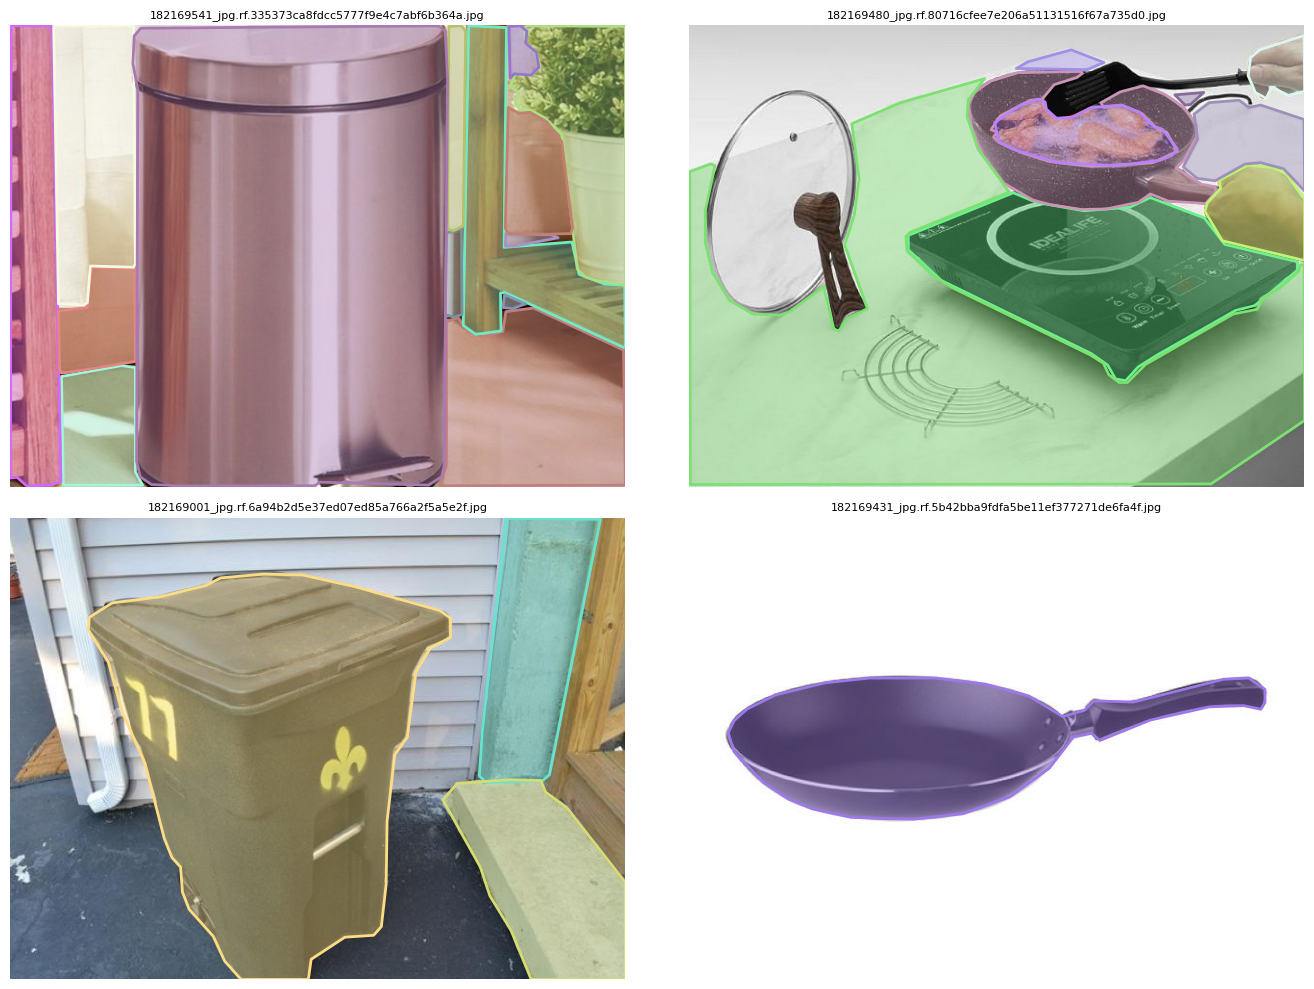

In [6]:
import matplotlib.pyplot as plt

preview_coco = COCO(str(TRAIN_ROOT / "train" / "_annotations.coco.json"))
sample_ids = random.Random(SEED).sample(list(preview_coco.imgs), min(4, len(preview_coco.imgs)))
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, image_id in zip(axes.flat, sample_ids):
    info = preview_coco.imgs[image_id]
    with Image.open(TRAIN_ROOT / "train" / info["file_name"]) as image:
        ax.imshow(image.convert("RGB"))
    plt.sca(ax)
    preview_coco.showAnns(preview_coco.imgToAnns[image_id])
    ax.set_title(info["file_name"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)
del preview_coco, fig, axes


## 4. Fungsi konversi COCO → YOLO Segmentation

In [7]:
import cv2
from pycocotools import mask as mask_utils


def to_polygon(segmentation, width, height):
    if isinstance(segmentation, list):
        if len(segmentation) == 1:
            return segmentation[0], False
        if len(segmentation) > 1:
            joined = np.concatenate(merge_multi_segment(segmentation), axis=0)
            return joined.flatten().tolist(), True
        raise ValueError("Segmentation kosong.")

    rle = segmentation
    if isinstance(rle["counts"], list):
        rle = mask_utils.frPyObjects(rle, height, width)
    mask = mask_utils.decode(rle).astype(np.uint8)
    if mask.ndim == 3:
        mask = mask[:, :, 0]
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c.reshape(-1, 2) for c in contours if len(c) >= 3]
    if not contours:
        raise ValueError("Mask RLE kosong atau tidak menghasilkan kontur.")

    joined = (
        np.concatenate(merge_multi_segment(contours), axis=0) if len(contours) > 1 else contours[0]
    )
    return joined.flatten().tolist(), len(contours) > 1


### Fungsi menulis label YOLO dari COCO

In [8]:
def coco_to_yolo(source_dir, split, output_root, prefix=""):
    doc = json.loads((source_dir / "_annotations.coco.json").read_text())
    cat_names = {c["id"]: c["name"] for c in doc["categories"]}
    image_dir = output_root / "images" / split
    label_dir = output_root / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    grouped = {}
    for ann in doc["annotations"]:
        grouped.setdefault(ann["image_id"], []).append(ann)
    rle_count = multipart_count = 0
    for im in doc["images"]:
        src = source_dir / im["file_name"]
        assert src.is_file(), src
        stem = prefix + src.stem
        dst = image_dir / (stem + src.suffix)
        if not dst.exists():
            os.symlink(src, dst)
        lines = []
        for ann in grouped.get(im["id"], []):
            name = cat_names[ann["category_id"]]
            if name not in NAME_TO_YOLO:
                raise ValueError(f"Kelas tidak dikenal: {name}")
            seg = ann["segmentation"]
            points, multipart = to_polygon(seg, im["width"], im["height"])
            rle_count += isinstance(seg, dict)
            multipart_count += multipart
            if len(points) < 6:
                raise ValueError(f'Polygon terlalu pendek: {ann["id"]}')
            coords = [
                min(1, max(0, v / (im["width"] if i % 2 == 0 else im["height"])))
                for i, v in enumerate(points)
            ]
            lines.append(str(NAME_TO_YOLO[name]) + " " + " ".join(f"{x:.6f}" for x in coords))
        (label_dir / (stem + ".txt")).write_text("\n".join(lines) + ("\n" if lines else ""))
    print(
        f'{split}: {len(doc["images"])} gambar, {len(doc["annotations"])} instance; {rle_count} RLE dikonversi, {multipart_count} multi-komponen'
    )
    if multipart_count:
        print(
            "PERHATIAN: YOLO menghubungkan komponen mask dengan garis tipis. COCO asli tetap utuh untuk RF-DETR."
        )


### Fungsi menulis konfigurasi YOLO

In [9]:
def write_yolo_yaml(root, target):
    cfg = {
        "path": str(root),
        "train": "train_samples.txt",
        "val": "images/valid",
        "names": {i: name for i, name in enumerate(TRAIN_NAMES)},
    }
    target.write_text(yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True))
    return target


## 5. Siapkan data YOLO

In [10]:
YOLO_ROOT = OUT / "yolo_data"
for split in ("train", "valid"):
    coco_to_yolo(TRAIN_ROOT / split, split, YOLO_ROOT)
labels_by_image = {image["id"]: set() for image in train_doc["images"]}
for annotation in train_doc["annotations"]:
    labels_by_image[annotation["image_id"]].add(annotation["category_id"])
image_frequency = Counter(label for labels in labels_by_image.values() for label in labels)
ordered_ids = list(labels_by_image)
random.Random(SEED).shuffle(ordered_ids)
rarity = {
    image_id: min((image_frequency[label] for label in labels), default=len(ordered_ids))
    for image_id, labels in labels_by_image.items()
}
candidates = sorted((i for i in ordered_ids if rarity[i] <= 5), key=rarity.get)
extra_ids = candidates[: len(ordered_ids) // 10]
train_files = {
    im["id"]: str(YOLO_ROOT / "images" / "train" / Path(im["file_name"]).name)
    for im in train_doc["images"]
}
sample_ids = list(train_files) + extra_ids
(YOLO_ROOT / "train_samples.txt").write_text("\n".join(train_files[i] for i in sample_ids) + "\n")
print(f"YOLO: {len(train_files)} foto train, {len(extra_ids)} pengulangan per epoch")
YOLO_YAML = write_yolo_yaml(YOLO_ROOT, OUT / "data.yaml")
print("YOLO data:", YOLO_YAML)


train: 395 gambar, 4470 instance; 0 RLE dikonversi, 0 multi-komponen
valid: 164 gambar, 2002 instance; 0 RLE dikonversi, 0 multi-komponen
YOLO: 395 foto train, 39 pengulangan per epoch
YOLO data: /kaggle/working/instance_results_20261124_235409/data.yaml


## 6. Fungsi training YOLO

In [11]:
settings.update({"mlflow": False, "wandb": False, "tensorboard": False})


def train_yolo(run_name, model_file):
    started = time.monotonic()
    model = YOLO(model_file)
    try:
        model.train(
            data=str(YOLO_YAML),
            epochs=YOLO_EPOCHS,
            imgsz=IMAGE_SIZE,
            batch=YOLO_BATCH,
            device=0,
            seed=SEED,
            deterministic=True,
            optimizer="AdamW",
            lr0=0.001,
            lrf=0.01,
            cos_lr=True,
            warmup_epochs=3,
            weight_decay=0.0005,
            patience=25,
            hsv_h=0.015,
            hsv_s=0.4,
            hsv_v=0.3,
            degrees=5.0,
            translate=0.1,
            scale=0.3,
            fliplr=0.5,
            flipud=0.0,
            mosaic=0.5,
            close_mosaic=15,
            mixup=0.0,
            copy_paste=0.0,
            mask_ratio=2,
            amp=True,
            cache="disk",
            workers=NUM_WORKERS,
            plots=False,
            save=True,
            project=str(OUT / "runs"),
            name=run_name,
            exist_ok=False,
        )
        best = Path(model.trainer.best)
        assert best.is_file(), best
        minutes = round((time.monotonic() - started) / 60, 2)
        print(run_name, "menit", minutes, "checkpoint", best)
        return best, minutes
    finally:
        del model
        release_memory()


YOLO_RUNS = {}


### 6a. YOLO11n-seg dengan pretrained

In [12]:
YOLO_RUNS["yolo11_pretrained"] = train_yolo("yolo11_pretrained", "yolo11n-seg.pt")


Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/instance_results_20261124_235409/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=2, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11_pretrained, nbs=64,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      9.94G      1.286      2.945      3.233      1.632          0         16        960: 100% ━━━━━━━━━━━━ 109/109 5.2it/s 21.1s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 4.7it/s 4.5s0.2s
                   all        164       2001      0.277     0.0842     0.0577     0.0352      0.293     0.0791     0.0535     0.0314

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      7.26G      1.283      2.792      2.984      1.605          0         46        960: 100% ━━━━━━━━━━━━ 109/109 5.1it/s 21.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 4.8it/s 4.4s0.2s
                   all        164       2001      0.424     0.0898     0.0718     0.0449      0.416     0.0839     0.0667     

### 6b. YOLO11n-seg tanpa pretrained (scratch)

In [13]:
YOLO_RUNS["yolo11_scratch"] = train_yolo("yolo11_scratch", "yolo11n-seg.yaml")


Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/instance_results_20261124_235409/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=2, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.yaml, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11_scratch, nbs=64, 

### 6c. YOLOv8n-seg dengan pretrained

In [14]:
YOLO_RUNS["yolov8_pretrained"] = train_yolo("yolov8_pretrained", "yolov8n-seg.pt")


Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/instance_results_20261124_235409/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=2, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolov8_pretrained, nbs=64,

## 7. Siapkan test dan anotasinya

In [15]:
own_names = {category["id"]: category["name"] for category in own_doc["categories"]}
remapped = {
    **own_doc,
    "categories": TRAIN_CATEGORIES,
    "annotations": [
        {**annotation, "category_id": TRAIN_NAME_TO_ID[own_names[annotation["category_id"]]]}
        for annotation in own_doc["annotations"]
    ],
}
ground_truth = COCO()
ground_truth.dataset = remapped
ground_truth.createIndex()
for annotation in ground_truth.anns.values():
    encoded = ground_truth.annToRLE(annotation)
    annotation["area"] = float(mask_utils.area(encoded))
    annotation["bbox"] = mask_utils.toBbox(encoded).tolist()
ground_truth_path = OUT / "test_ground_truth.coco.json"
ground_truth_path.write_text(json.dumps(remapped), encoding="utf-8")
assert len(ground_truth.imgs) == 40


creating index...
index created!


In [16]:
eval_test = OUT / "inference_images"
eval_test.mkdir(parents=True, exist_ok=True)
image_paths = {}
for info in own_doc["images"]:
    source = TEST_ROOT / info["file_name"]
    image = cv2.imread(str(source))
    if image is None:
        raise FileNotFoundError(source)
    height, width = image.shape[:2]
    assert (width, height) == (info["width"], info["height"]), source
    scale = min(1.0, EVAL_MAX_SIDE / max(width, height))
    destination = eval_test / f"{info['id']}.png"
    size = (max(1, round(width * scale)), max(1, round(height * scale)))
    resized = cv2.resize(image, size, interpolation=cv2.INTER_AREA)
    assert cv2.imwrite(str(destination), resized), destination
    image_paths[info["id"]] = destination
    del image, resized
print("Inference images:", len(image_paths))


Inference images: 40


In [17]:
from pycocotools.cocoeval import COCOeval


def encode_prediction(mask, image_info, category_id, confidence):
    size = (image_info["width"], image_info["height"])
    restored = cv2.resize(mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST)
    encoded = mask_utils.encode(np.asfortranarray(restored))
    if mask_utils.area(encoded) == 0:
        return None
    encoded["counts"] = encoded["counts"].decode("ascii")
    return {
        "image_id": image_info["id"],
        "category_id": int(category_id),
        "segmentation": encoded,
        "score": float(confidence),
    }


def preview_mask(mask, category_id, confidence):
    height, width = mask.shape
    scale = min(1.0, 640 / max(height, width))
    size = (max(1, round(width * scale)), max(1, round(height * scale)))
    small = cv2.resize(mask.astype(np.uint8), size, interpolation=cv2.INTER_NEAREST)
    encoded = mask_utils.encode(np.asfortranarray(small))
    encoded["counts"] = encoded["counts"].decode("ascii")
    return {"category_id": int(category_id), "score": float(confidence), "segmentation": encoded}


def save_preview(model_name, image_id, records):
    folder = OUT / "preview_masks" / model_name
    folder.mkdir(parents=True, exist_ok=True)
    (folder / f"{image_id}.json").write_text(json.dumps(records, separators=(",", ":")))


def mean_valid(values):
    values = np.asarray(values)
    valid = values[values >= 0]
    return float(valid.mean()) if valid.size else float("nan")


def evaluate_predictions(predictions, run_name, family, pretrained, minutes):
    (OUT / f"{run_name}_predictions.coco.json").write_text(json.dumps(predictions))
    if predictions:
        detected = ground_truth.loadRes(predictions)
    else:
        detected = COCO()
        detected.dataset = {
            "images": ground_truth.dataset["images"],
            "categories": ground_truth.dataset["categories"],
            "annotations": [],
        }
        detected.createIndex()
    evaluator = COCOeval(ground_truth, detected, "segm")
    evaluator.params.catIds = sorted({a["category_id"] for a in ground_truth.anns.values()})
    evaluator.params.maxDets = [1, 10, 100, MAX_DETECTIONS]
    evaluator.evaluate()
    evaluator.accumulate()
    precision = evaluator.eval["precision"]
    recall = evaluator.eval["recall"]
    result = {
        "model": run_name,
        "family": family,
        "pretrained": pretrained,
        "test_set": "foto_pribadi_40",
        "mask_mAP50_95": mean_valid(precision[:, :, :, 0, 2]),
        "mask_mAP50": mean_valid(precision[0, :, :, 0, 2]),
        "mask_mAP50_95_dense": mean_valid(precision[:, :, :, 0, -1]),
        "mask_recall_dense": mean_valid(recall[:, :, 0, -1]),
        "train_minutes": minutes,
    }
    class_rows = []
    for index, category_id in enumerate(evaluator.params.catIds):
        name = ground_truth.cats[category_id]["name"]
        class_rows.append(
            {
                "class": name,
                "train_instances": train_counts[name],
                "valid_instances": valid_counts[name],
                "test_instances": test_counts[name],
                "mask_mAP50_95": mean_valid(precision[:, :, index, 0, 2]),
                "mask_mAP50": mean_valid(precision[0, :, index, 0, 2]),
                "mask_mAP50_95_dense": mean_valid(precision[:, :, index, 0, -1]),
            }
        )
    pd.DataFrame(class_rows).to_csv(OUT / f"{run_name}_per_class.csv", index=False)
    return result


## 8. Evaluasi ketiga YOLO pada test

In [18]:
rows = []
for run_name, (best, minutes) in YOLO_RUNS.items():
    model = YOLO(str(best))
    predictions = []
    try:
        for info in own_doc["images"]:
            preview_records = []
            prediction = model.predict(
                source=str(image_paths[info["id"]]),
                imgsz=IMAGE_SIZE,
                conf=0.001,
                iou=0.7,
                max_det=MAX_DETECTIONS,
                retina_masks=False,
                device=0,
                verbose=False,
            )[0].cpu()
            if prediction.masks is not None:
                for mask, category, confidence in zip(
                    prediction.masks.data, prediction.boxes.cls, prediction.boxes.conf
                ):
                    resized = scale_masks(mask[None, None].float(), prediction.orig_shape)[0, 0]
                    category_id = TRAIN_NAME_TO_ID[model.names[int(category)]]
                    binary_mask = resized.numpy() > 0.5
                    record = encode_prediction(binary_mask, info, category_id, float(confidence))
                    if record is not None:
                        predictions.append(record)
                        if float(confidence) >= 0.05:
                            preview_records.append(
                                preview_mask(binary_mask, category_id, float(confidence))
                            )
                    del resized
            save_preview(run_name, info["id"], preview_records)
            del prediction
        rows.append(
            evaluate_predictions(
                predictions, run_name, "CNN", run_name != "yolo11_scratch", minutes
            )
        )
        pd.DataFrame(rows).to_csv(OUT / "results.csv", index=False)
    finally:
        del model, predictions
        release_memory()
display(pd.DataFrame(rows))


Loading and preparing results...
DONE (t=0.90s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=6.24s).
Accumulating evaluation results...
DONE (t=0.46s).
Loading and preparing results...
DONE (t=3.18s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=5.84s).
Accumulating evaluation results...
DONE (t=0.44s).
Loading and preparing results...
DONE (t=0.91s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.84s).
Accumulating evaluation results...
DONE (t=0.42s).


,model,family,pretrained,test_set,mask_mAP50_95,mask_mAP50,mask_mAP50_95_dense,mask_recall_dense,train_minutes
0,yolo11_pretrained,CNN,True,foto_pribadi_40,0.030462,0.054651,0.030685,0.090999,43.32
1,yolo11_scratch,CNN,False,foto_pribadi_40,0.001538,0.003865,0.001546,0.016348,30.95
2,yolov8_pretrained,CNN,True,foto_pribadi_40,0.029060,0.050556,0.029122,0.077259,37.55


## 9. Training RF-DETR Seg Nano (transformer)

In [ ]:
rf_model = RFDETRSegNano(resolution=480)
rf_out = OUT / "runs" / "rfdetr_seg_nano"
started = time.monotonic()
try:
    rf_model.train(
        dataset_dir=str(TRAIN_ROOT),
        output_dir=str(rf_out),
        epochs=RF_EPOCHS,
        batch_size=RF_BATCH,
        eval_batch_size=1,
        grad_accum_steps=4,
        lr=1e-4,
        early_stopping=True,
        early_stopping_patience=15,
        seed=SEED,
        tensorboard=False,
        amp_dtype="auto",
        num_workers=NUM_WORKERS,
        prefetch_factor=1,
    )
    rf_minutes = round((time.monotonic() - started) / 60, 2)
    rf_best = rf_out / "checkpoint_best_total.pth"
    assert rf_best.is_file(), rf_best
finally:
    del rf_model
    release_memory()
print("RF-DETR training minutes:", rf_minutes)


[2026-11-25 02:21:05] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-seg-nano.pt


/root/.roboflow/models/rf-detr-seg-nano.pt:   0%|          | 0.00/128M [00:00<?, ?iB/s]

[2026-11-25 02:21:07] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-seg-nano.pt
[2026-11-25 02:21:08] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-seg-nano.pt already exists with correct MD5 hash.
[2026-11-25 02:21:09] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-seg-nano.pt already exists with correct MD5 hash.


[2026-11-25 02:21:10] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 74. The detection head will be re-initialized to 74 classes.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


[2026-11-25 02:21:10] [INFO] rf-detr - Building Roboflow train dataset with square resize at resolution 480
[2026-11-25 02:21:10] [INFO] rf-detr - Using multi-scale training with square resize and scales: [540]
[2026-11-25 02:21:10] [INFO] rf-detr - Built 1 Albumentations transforms from config
[2026-11-25 02:21:10] [INFO] rf-detr - Built 1 Albumentations transforms from config
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
[2026-11-25 02:21:10] [INFO] rf-detr - Skipping unannotated COCO grouping categories when assigning label indices: 0 (indoor-objects)


/usr/local/lib/python3.13/dist-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory /kaggle/working/instance_results_20261124_235409/runs/rfdetr_seg_nano/ exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!


... (17 outputs left out)

Metric __rfdetr_effective_map__ improved by 0.013 >= min_delta = 0.001. New best score: 0.149


[2026-11-25 02:29:33] [INFO] rf-detr - Best EMA metric improved to 0.1488 (epoch 5)


Metric __rfdetr_effective_map__ improved by 0.014 >= min_delta = 0.001. New best score: 0.162


[2026-11-25 02:30:57] [INFO] rf-detr - Best EMA metric improved to 0.1623 (epoch 6)


## 10. Evaluasi RF-DETR pada test

In [25]:
rf_model = RFDETR.from_checkpoint(str(rf_best))
rf_names = rf_model.class_names
assert set(rf_names) == set(TRAIN_NAMES), rf_names
predictions = []
try:
    for info in own_doc["images"]:
        preview_records = []
        image = cv2.imread(str(image_paths[info["id"]]))
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        detections = rf_model.predict(image_rgb, threshold=0.001)
        if detections.mask is not None:
            order = np.argsort(-detections.confidence)[:MAX_DETECTIONS]
            for index in order:
                class_index = int(detections.class_id[index])
                if not 0 <= class_index < len(rf_names):
                    continue
                category_id = TRAIN_NAME_TO_ID[rf_names[class_index]]
                record = encode_prediction(
                    detections.mask[index], info, category_id, detections.confidence[index]
                )
                if record is not None:
                    predictions.append(record)
                    if float(detections.confidence[index]) >= 0.05:
                        preview_records.append(
                            preview_mask(
                                detections.mask[index],
                                category_id,
                                float(detections.confidence[index]),
                            )
                        )
        save_preview("rfdetr_seg_nano", info["id"], preview_records)
        del image, image_rgb, detections
    rows = [row for row in rows if row["model"] != "rfdetr_seg_nano"]
    rows.append(
        evaluate_predictions(predictions, "rfdetr_seg_nano", "Transformer", True, rf_minutes)
    )
finally:
    del rf_model, predictions
    release_memory()
results = pd.DataFrame(rows)
results.to_csv(OUT / "results.csv", index=False)
display(results)


[2026-11-25 05:23:07] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Loading and preparing results...
DONE (t=0.15s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=1.13s).
Accumulating evaluation results...
DONE (t=0.25s).


,model,family,pretrained,test_set,mask_mAP50_95,mask_mAP50,mask_mAP50_95_dense,mask_recall_dense,train_minutes
0,yolo11_pretrained,CNN,True,foto_pribadi_40,0.030462,0.054651,0.030685,0.090999,43.32
1,yolo11_scratch,CNN,False,foto_pribadi_40,0.001538,0.003865,0.001546,0.016348,30.95
2,yolov8_pretrained,CNN,True,foto_pribadi_40,0.029060,0.050556,0.029122,0.077259,37.55
3,rfdetr_seg_nano,Transformer,True,foto_pribadi_40,0.084059,0.128723,0.084059,0.144613,84.61


## 11. Evaluasi RF-DETR pada test panoptic

In [30]:
panoptic_test_dir = TRAIN_DIR.parent / "test"
panoptic_test_json = panoptic_test_dir / "_annotations.coco.json"
assert panoptic_test_json.is_file(), panoptic_test_json
panoptic_ground_truth = COCO(str(panoptic_test_json))
assert {item["name"] for item in panoptic_ground_truth.cats.values()} == {
    item["name"] for item in TRAIN_CATEGORIES
}
for annotation in panoptic_ground_truth.anns.values():
    encoded = panoptic_ground_truth.annToRLE(annotation)
    annotation["area"] = float(mask_utils.area(encoded))
    annotation["bbox"] = mask_utils.toBbox(encoded).tolist()

panoptic_rows = []
panoptic_categories = sorted({ann["category_id"] for ann in panoptic_ground_truth.anns.values()})


def evaluate_panoptic_test(model_name, predictions):
    prediction_file = OUT / f"{model_name}_panoptic_test_predictions.coco.json"
    prediction_file.write_text(json.dumps(predictions))
    if predictions:
        detected = panoptic_ground_truth.loadRes(predictions)
    else:
        detected = COCO()
        detected.dataset = {
            "images": panoptic_ground_truth.dataset["images"],
            "categories": panoptic_ground_truth.dataset["categories"],
            "annotations": [],
        }
        detected.createIndex()
    evaluator = COCOeval(panoptic_ground_truth, detected, "segm")
    evaluator.params.catIds = panoptic_categories
    evaluator.params.maxDets = [1, 10, 100, MAX_DETECTIONS]
    evaluator.evaluate()
    evaluator.accumulate()
    precision = evaluator.eval["precision"]
    recall = evaluator.eval["recall"]
    return {
        "model": model_name,
        "test_set": "panoptic_v5_test",
        "images": len(panoptic_ground_truth.imgs),
        "instances": len(panoptic_ground_truth.anns),
        "mask_mAP50_95": mean_valid(precision[:, :, :, 0, 2]),
        "mask_mAP50": mean_valid(precision[0, :, :, 0, 2]),
        "mask_mAP50_95_dense": mean_valid(precision[:, :, :, 0, -1]),
        "mask_recall_dense": mean_valid(recall[:, :, 0, -1]),
    }


for model_name, (checkpoint, _) in YOLO_RUNS.items():
    model = YOLO(str(checkpoint))
    predictions = []
    try:
        for info in panoptic_ground_truth.dataset["images"]:
            source = panoptic_test_dir / info["file_name"]
            prediction = model.predict(
                source=str(source),
                imgsz=IMAGE_SIZE,
                conf=0.001,
                iou=0.7,
                max_det=MAX_DETECTIONS,
                retina_masks=False,
                device=0,
                verbose=False,
            )[0].cpu()
            if prediction.masks is not None:
                for mask, category, confidence in zip(
                    prediction.masks.data, prediction.boxes.cls, prediction.boxes.conf
                ):
                    resized = scale_masks(mask[None, None].float(), prediction.orig_shape)[0, 0]
                    category_id = TRAIN_NAME_TO_ID[model.names[int(category)]]
                    record = encode_prediction(resized.numpy() > 0.5, info, category_id, confidence)
                    if record is not None:
                        predictions.append(record)
                    del resized
            del prediction
        panoptic_rows.append(evaluate_panoptic_test(model_name, predictions))
    finally:
        del model, predictions
        release_memory()
    pd.DataFrame(panoptic_rows).to_csv(OUT / "panoptic_test_results.csv", index=False)

rf_model = RFDETR.from_checkpoint(str(rf_best))
rf_names = rf_model.class_names
assert set(rf_names) == set(TRAIN_NAMES), rf_names
predictions = []
try:
    for info in panoptic_ground_truth.dataset["images"]:
        image = cv2.imread(str(panoptic_test_dir / info["file_name"]))
        if image is None:
            raise FileNotFoundError(info["file_name"])
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        detections = rf_model.predict(image_rgb, threshold=0.001, include_source_image=False)
        if detections.mask is not None:
            order = np.argsort(-detections.confidence)[:MAX_DETECTIONS]
            for index in order:
                class_index = int(detections.class_id[index])
                if not 0 <= class_index < len(rf_names):
                    continue
                category_id = TRAIN_NAME_TO_ID[rf_names[class_index]]
                record = encode_prediction(
                    detections.mask[index], info, category_id, detections.confidence[index]
                )
                if record is not None:
                    predictions.append(record)
        del image, image_rgb, detections
    panoptic_rows.append(evaluate_panoptic_test("rfdetr_seg_nano", predictions))
finally:
    del rf_model, predictions
    release_memory()

panoptic_results = pd.DataFrame(panoptic_rows)
panoptic_results.to_csv(OUT / "panoptic_test_results.csv", index=False)
display(panoptic_results.round(4))

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.79s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=7.86s).
Accumulating evaluation results...
DONE (t=2.15s).
Loading and preparing results...
DONE (t=7.79s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=13.52s).
Accumulating evaluation results...
DONE (t=3.42s).
Loading and preparing results...
DONE (t=2.18s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=8.01s).
Accumulating evaluation results...
DONE (t=2.38s).


[2026-11-25 06:33:08] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


Loading and preparing results...
DONE (t=0.70s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=3.69s).
Accumulating evaluation results...
DONE (t=1.54s).


,model,test_set,images,instances,mask_mAP50_95,mask_mAP50,mask_mAP50_95_dense,mask_recall_dense
0,yolo11_pretrained,panoptic_v5_test,359,5344,0.0560,0.0936,0.0561,0.1782
1,yolo11_scratch,panoptic_v5_test,359,5344,0.0068,0.0145,0.0068,0.0504
2,yolov8_pretrained,panoptic_v5_test,359,5344,0.0482,0.0795,0.0482,0.1671
3,rfdetr_seg_nano,panoptic_v5_test,359,5344,0.1837,0.2573,0.1837,0.3963


## 12a. Visualisasi Hasil Segmentasi Pada Data Test Set Panoptic

In [42]:
from collections import Counter
from functools import lru_cache
from pathlib import Path

import cv2
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO


panoptic_test_dir = TRAIN_DIR.parent / "test"
panoptic_ground_truth = COCO(
    str(panoptic_test_dir / "_annotations.coco.json")
)
panoptic_class_names = {
    class_id: category["name"]
    for class_id, category in panoptic_ground_truth.cats.items()
}

panoptic_models = [
    "yolo11_pretrained",
    "yolo11_scratch",
    "yolov8_pretrained",
    "rfdetr_seg_nano",
]

for model_name in panoptic_models:
    prediction_file = OUT / (
        f"{model_name}_panoptic_test_predictions.coco.json"
    )
    assert prediction_file.is_file(), prediction_file


def panoptic_color(class_id):
    channels = plt.get_cmap("tab20")((class_id * 7) % 20)[:3]
    return tuple(round(channel * 255) for channel in channels)


@lru_cache(maxsize=1)
def load_panoptic_photo(image_id):
    info = panoptic_ground_truth.imgs[image_id]
    image_path = panoptic_test_dir / info["file_name"]

    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(image_path)

    height, width = image.shape[:2]
    scale = min(1.0, 640 / max(height, width))
    size = (
        max(1, round(width * scale)),
        max(1, round(height * scale)),
    )

    image = cv2.resize(
        image,
        size,
        interpolation=cv2.INTER_AREA,
    )
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    annotations = [
        (
            annotation["category_id"],
            panoptic_ground_truth.annToRLE(annotation),
        )
        for annotation in panoptic_ground_truth.imgToAnns[image_id]
    ]

    return rgb, annotations


@lru_cache(maxsize=1)
def load_panoptic_predictions(model_name):
    prediction_file = OUT / (
        f"{model_name}_panoptic_test_predictions.coco.json"
    )
    records = pd.read_json(prediction_file)

    by_image = {
        image_id: []
        for image_id in panoptic_ground_truth.imgs
    }

    for record in records.to_dict("records"):
        if record["score"] >= 0.05:
            by_image[record["image_id"]].append(record)

    return by_image


def place_panoptic_label(canvas, name, contour, occupied):
    height, width = canvas.shape[:2]
    x, y, box_width, box_height = cv2.boundingRect(contour)

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.48
    (text_width, text_height), _ = cv2.getTextSize(
        name,
        font,
        font_scale,
        1,
    )

    label_width = text_width + 10
    label_height = text_height + 10
    label_x = max(0, min(x, width - label_width))

    positions = [
        max(0, y - label_height),
        min(height - label_height, y + 5),
        min(height - label_height, y + box_height - label_height),
    ]

    label_y = positions[0]

    for candidate in positions:
        rectangle = (
            label_x,
            candidate,
            label_x + label_width,
            candidate + label_height,
        )

        overlaps = any(
            rectangle[0] < previous[2]
            and rectangle[2] > previous[0]
            and rectangle[1] < previous[3]
            and rectangle[3] > previous[1]
            for previous in occupied
        )

        if not overlaps:
            label_y = candidate
            break

    rectangle = (
        label_x,
        label_y,
        label_x + label_width,
        label_y + label_height,
    )
    occupied.append(rectangle)

    cv2.rectangle(
        canvas,
        rectangle[:2],
        rectangle[2:],
        (25, 25, 25),
        -1,
    )
    cv2.putText(
        canvas,
        name,
        (label_x + 5, label_y + text_height + 4),
        font,
        font_scale,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )


def draw_panoptic_regions(image, regions, selected_class):
    canvas = image.copy()
    counts = Counter()
    label_targets = {}

    for class_id, segmentation in regions:
        if selected_class is not None and class_id != selected_class:
            continue

        mask = mask_utils.decode(segmentation).astype(np.uint8)
        if mask.shape != image.shape[:2]:
            mask = cv2.resize(
                mask,
                image.shape[1::-1],
                interpolation=cv2.INTER_NEAREST,
            )

        contours, _ = cv2.findContours(
            mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )
        if not contours:
            continue

        name = panoptic_class_names[class_id]
        color = panoptic_color(class_id)
        active = mask.astype(bool)

        canvas[active] = (
            0.55 * canvas[active] + 0.45 * np.asarray(color)
        ).astype(np.uint8)
        cv2.drawContours(canvas, contours, -1, color, 1)
        counts[name] += 1

        largest = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(largest)

        label_key = name if selected_class is None else len(label_targets)
        if label_key not in label_targets or area > label_targets[label_key][0]:
            label_targets[label_key] = (area, name, largest)

    occupied = []
    for _, name, contour in sorted(
        label_targets.values(),
        key=lambda item: item[0],
        reverse=True,
    ):
        place_panoptic_label(canvas, name, contour, occupied)

    return canvas, counts


def show_panoptic_photo(image_id, model_name, category_id, confidence):
    original, annotations = load_panoptic_photo(image_id)
    prediction_records = load_panoptic_predictions(model_name)[image_id]

    predictions = [
        (record["category_id"], record["segmentation"])
        for record in prediction_records
        if record["score"] >= confidence
    ]

    annotated, actual_counts = draw_panoptic_regions(
        original,
        annotations,
        category_id,
    )
    predicted, predicted_counts = draw_panoptic_regions(
        original,
        predictions,
        category_id,
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 6),
        constrained_layout=True,
    )

    for ax, picture, title in zip(
        axes,
        [original, annotated, predicted],
        [
            "Foto asli",
            f"Anotasi · {sum(actual_counts.values())} instance",
            f"Prediksi · {sum(predicted_counts.values())} instance",
        ],
    ):
        ax.imshow(picture)
        ax.set_title(title)
        ax.axis("off")

    display(fig)
    plt.close(fig)

    class_counts = pd.DataFrame(
        {
            "Anotasi": actual_counts,
            "Prediksi": predicted_counts,
        }
    ).fillna(0).astype(int)

    if not class_counts.empty:
        display(
            class_counts.sort_values(
                ["Anotasi", "Prediksi"],
                ascending=False,
            )
        )


panoptic_photos = sorted(
    panoptic_ground_truth.imgs.values(),
    key=lambda info: info["file_name"],
)
panoptic_class_ids = sorted({
    annotation["category_id"]
    for annotation in panoptic_ground_truth.anns.values()
})

photo_choice = widgets.Dropdown(
    options=[
        (info["file_name"], info["id"])
        for info in panoptic_photos
    ],
    description="Foto",
)
model_choice = widgets.Dropdown(
    options=panoptic_models,
    description="Model",
)
class_choice = widgets.Dropdown(
    options=[("Semua kelas", None)] + [
        (panoptic_class_names[class_id], class_id)
        for class_id in panoptic_class_ids
    ],
    description="Kelas",
)
score_choice = widgets.FloatSlider(
    value=0.35,
    min=0.05,
    max=1.0,
    step=0.05,
    description="Skor min.",
    continuous_update=False,
)

viewer = widgets.interactive_output(
    show_panoptic_photo,
    {
        "image_id": photo_choice,
        "model_name": model_choice,
        "category_id": class_choice,
        "confidence": score_choice,
    },
)

display(
    widgets.VBox(
        [
            widgets.HBox([photo_choice, model_choice]),
            widgets.HBox([class_choice, score_choice]),
            viewer,
        ]
    )
)

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!


## 12b. Visualisasi hasil segmentasi Pada Data Test 40 Foto

In [43]:
from collections import Counter
from functools import lru_cache
from pathlib import Path

import cv2
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pycocotools import mask as mask_utils


personal_photos = sorted(
    own_doc["images"],
    key=lambda info: info["file_name"],
)
personal_models = results["model"].tolist()
personal_class_names = {
    class_id: category["name"]
    for class_id, category in ground_truth.cats.items()
}


def personal_color(class_id):
    channels = plt.get_cmap("tab20")((class_id * 7) % 20)[:3]
    return tuple(round(channel * 255) for channel in channels)


@lru_cache(maxsize=1)
def load_personal_photo(image_id):
    image_path = image_paths[image_id]
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(image_path)

    height, width = image.shape[:2]
    scale = min(1.0, 640 / max(height, width))
    size = (
        max(1, round(width * scale)),
        max(1, round(height * scale)),
    )

    image = cv2.resize(
        image,
        size,
        interpolation=cv2.INTER_AREA,
    )
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    annotations = [
        (
            annotation["category_id"],
            ground_truth.annToRLE(annotation),
        )
        for annotation in ground_truth.imgToAnns[image_id]
    ]

    return rgb, annotations


def place_personal_label(canvas, name, contour, occupied):
    height, width = canvas.shape[:2]
    x, y, box_width, box_height = cv2.boundingRect(contour)

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.48
    (text_width, text_height), _ = cv2.getTextSize(
        name,
        font,
        font_scale,
        1,
    )

    label_width = text_width + 10
    label_height = text_height + 10
    label_x = max(0, min(x, width - label_width))

    positions = [
        max(0, y - label_height),
        min(height - label_height, y + 5),
        min(height - label_height, y + box_height - label_height),
    ]

    label_y = positions[0]

    for candidate in positions:
        rectangle = (
            label_x,
            candidate,
            label_x + label_width,
            candidate + label_height,
        )

        overlaps = any(
            rectangle[0] < previous[2]
            and rectangle[2] > previous[0]
            and rectangle[1] < previous[3]
            and rectangle[3] > previous[1]
            for previous in occupied
        )

        if not overlaps:
            label_y = candidate
            break

    rectangle = (
        label_x,
        label_y,
        label_x + label_width,
        label_y + label_height,
    )
    occupied.append(rectangle)

    cv2.rectangle(
        canvas,
        rectangle[:2],
        rectangle[2:],
        (25, 25, 25),
        -1,
    )
    cv2.putText(
        canvas,
        name,
        (label_x + 5, label_y + text_height + 4),
        font,
        font_scale,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )


def draw_personal_regions(image, regions, selected_class):
    canvas = image.copy()
    counts = Counter()
    label_targets = {}

    for class_id, segmentation in regions:
        if selected_class is not None and class_id != selected_class:
            continue

        mask = mask_utils.decode(segmentation).astype(np.uint8)

        if mask.shape != image.shape[:2]:
            mask = cv2.resize(
                mask,
                image.shape[1::-1],
                interpolation=cv2.INTER_NEAREST,
            )

        contours, _ = cv2.findContours(
            mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )

        if not contours:
            continue

        name = personal_class_names[class_id]
        color = personal_color(class_id)
        active = mask.astype(bool)

        canvas[active] = (
            0.55 * canvas[active] + 0.45 * np.asarray(color)
        ).astype(np.uint8)
        cv2.drawContours(canvas, contours, -1, color, 1)
        counts[name] += 1

        largest = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(largest)
        label_key = name if selected_class is None else len(label_targets)

        if label_key not in label_targets or area > label_targets[label_key][0]:
            label_targets[label_key] = (area, name, largest)

    occupied = []

    for _, name, contour in sorted(
        label_targets.values(),
        key=lambda item: item[0],
        reverse=True,
    ):
        place_personal_label(canvas, name, contour, occupied)

    return canvas, counts


def compare_personal_photo(image_id, model_name, class_id, min_score):
    original, annotations = load_personal_photo(image_id)

    prediction_file = (
        OUT / "preview_masks" / model_name / f"{image_id}.json"
    )
    if not prediction_file.is_file():
        raise FileNotFoundError(prediction_file)

    records = json.loads(prediction_file.read_text())
    predictions = [
        (record["category_id"], record["segmentation"])
        for record in records
        if record["score"] >= min_score
    ]

    annotated, actual_counts = draw_personal_regions(
        original,
        annotations,
        class_id,
    )
    predicted, predicted_counts = draw_personal_regions(
        original,
        predictions,
        class_id,
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 6),
        constrained_layout=True,
    )

    for ax, picture, title in zip(
        axes,
        [original, annotated, predicted],
        [
            "Foto asli",
            f"Anotasi · {sum(actual_counts.values())} instance",
            f"Prediksi · {sum(predicted_counts.values())} instance",
        ],
    ):
        ax.imshow(picture)
        ax.set_title(title)
        ax.axis("off")

    class_counts = pd.DataFrame(
        {
            "Anotasi": actual_counts,
            "Prediksi": predicted_counts,
        }
    ).fillna(0).astype(int)

    return fig, class_counts


def show_personal_photo(image_id, model_name, class_id, min_score):
    fig, class_counts = compare_personal_photo(
        image_id,
        model_name,
        class_id,
        min_score,
    )

    display(fig)
    plt.close(fig)

    if not class_counts.empty:
        display(
            class_counts.sort_values(
                ["Anotasi", "Prediksi"],
                ascending=False,
            )
        )


personal_class_ids = sorted({
    annotation["category_id"]
    for annotation in ground_truth.anns.values()
})

photo_choice = widgets.Dropdown(
    options=[
        (
            info.get("extra", {}).get("name", info["file_name"]),
            info["id"],
        )
        for info in personal_photos
    ],
    description="Foto",
)
model_choice = widgets.Dropdown(
    options=personal_models,
    description="Model",
)
class_choice = widgets.Dropdown(
    options=[("Semua kelas", None)] + [
        (personal_class_names[class_id], class_id)
        for class_id in personal_class_ids
    ],
    description="Kelas",
)
score_choice = widgets.FloatSlider(
    value=0.35,
    min=0.05,
    max=1.0,
    step=0.05,
    description="Skor min.",
    continuous_update=False,
)

personal_viewer = widgets.interactive_output(
    show_personal_photo,
    {
        "image_id": photo_choice,
        "model_name": model_choice,
        "class_id": class_choice,
        "min_score": score_choice,
    },
)

display(
    widgets.VBox(
        [
            widgets.HBox([photo_choice, model_choice]),
            widgets.HBox([class_choice, score_choice]),
            personal_viewer,
        ]
    )
)

for photo_index in (0, 20):
    fig, _ = compare_personal_photo(
        personal_photos[photo_index]["id"],
        personal_models[0],
        None,
        0.35,
    )
    fig.savefig(
        OUT / f"comparison_{photo_index}.png",
        dpi=140,
        bbox_inches="tight",
    )
    plt.close(fig)

## 13a. 5 Foto di mana model gagal

In [49]:
from collections import Counter, defaultdict
import json

import numpy as np
import pandas as pd
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO


ground_truth_file = OUT / "test_ground_truth.coco.json"
assert ground_truth_file.is_file(), ground_truth_file

test_ground_truth = COCO(str(ground_truth_file))
class_names = {
    class_id: category["name"]
    for class_id, category in test_ground_truth.cats.items()
}

model_scores = pd.read_csv(OUT / "results.csv")
models = model_scores["model"].tolist()
selected_model = model_scores.loc[
    model_scores["mask_mAP50_95"].idxmax(),
    "model",
]

min_confidence = 0.35
match_iou = 0.50

rows = []


def assess_photo(image_id, annotations, predictions, model_name):
    annotations = [
        item for item in annotations
        if not item.get("iscrowd", 0)
    ]
    predictions = sorted(
        predictions,
        key=lambda item: item["score"],
        reverse=True,
    )

    actual_masks = [
        test_ground_truth.annToRLE(item)
        for item in annotations
    ]
    predicted_masks = [
        item["segmentation"]
        for item in predictions
    ]

    if annotations and predictions:
        overlaps = mask_utils.iou(
            predicted_masks,
            actual_masks,
            [0] * len(annotations),
        )
    else:
        overlaps = np.zeros(
            (len(predictions), len(annotations)),
            dtype=float,
        )

    matched_predictions = set()
    matched_annotations = set()
    matched_ious = []

    for pred_index, prediction in enumerate(predictions):
        candidates = [
            ann_index
            for ann_index, annotation in enumerate(annotations)
            if ann_index not in matched_annotations
            and prediction["category_id"] == annotation["category_id"]
            and overlaps[pred_index, ann_index] >= match_iou
        ]

        if not candidates:
            continue

        ann_index = max(
            candidates,
            key=lambda index: overlaps[pred_index, index],
        )
        matched_predictions.add(pred_index)
        matched_annotations.add(ann_index)
        matched_ious.append(float(overlaps[pred_index, ann_index]))

    wrong_class_examples = []
    used_wrong_annotations = set()

    for pred_index, prediction in enumerate(predictions):
        if pred_index in matched_predictions:
            continue

        candidates = [
            ann_index
            for ann_index, annotation in enumerate(annotations)
            if ann_index not in matched_annotations
            and ann_index not in used_wrong_annotations
            and prediction["category_id"] != annotation["category_id"]
            and overlaps[pred_index, ann_index] >= match_iou
        ]

        if not candidates:
            continue

        ann_index = max(
            candidates,
            key=lambda index: overlaps[pred_index, index],
        )
        used_wrong_annotations.add(ann_index)

        actual_name = class_names[annotations[ann_index]["category_id"]]
        predicted_name = class_names[prediction["category_id"]]
        wrong_class_examples.append(
            f"{actual_name} → {predicted_name}"
        )

    leaking_masks = 0

    for pred_index, prediction in enumerate(predictions):
        same_class = [
            ann_index
            for ann_index, annotation in enumerate(annotations)
            if prediction["category_id"] == annotation["category_id"]
            and overlaps[pred_index, ann_index] >= 0.25
        ]

        if not same_class:
            continue

        ann_index = max(
            same_class,
            key=lambda index: overlaps[pred_index, index],
        )
        iou = float(overlaps[pred_index, ann_index])

        predicted_area = float(
            mask_utils.area(predicted_masks[pred_index])
        )
        actual_area = float(
            mask_utils.area(actual_masks[ann_index])
        )

        intersection = (
            iou * (predicted_area + actual_area) / (1 + iou)
        )
        outside_ratio = 1 - intersection / predicted_area

        if outside_ratio >= 0.30:
            leaking_masks += 1

    split_or_duplicate = 0

    for ann_index, annotation in enumerate(annotations):
        overlapping_predictions = sum(
            prediction["category_id"] == annotation["category_id"]
            and overlaps[pred_index, ann_index] >= 0.10
            for pred_index, prediction in enumerate(predictions)
        )

        if overlapping_predictions >= 2:
            split_or_duplicate += 1

    true_positives = len(matched_predictions)
    false_positives = len(predictions) - true_positives
    false_negatives = len(annotations) - true_positives

    denominator = (
        2 * true_positives + false_positives + false_negatives
    )
    f1 = (
        2 * true_positives / denominator
        if denominator else 1.0
    )

    missed_classes = Counter(
        class_names[annotation["category_id"]]
        for ann_index, annotation in enumerate(annotations)
        if ann_index not in matched_annotations
    )

    image_info = test_ground_truth.imgs[image_id]

    return {
        "model": model_name,
        "foto": image_info["file_name"],
        "image_id": image_id,
        "anotasi": len(annotations),
        "prediksi": len(predictions),
        "terdeteksi_benar": true_positives,
        "tidak_terdeteksi": false_negatives,
        "prediksi_tidak_cocok": false_positives,
        "F1_mask_IoU_50": f1,
        "rata_rata_IoU_mask_cocok": (
            np.mean(matched_ious)
            if matched_ious else 0.0
        ),
        "indikasi_salah_kelas": len(wrong_class_examples),
        "indikasi_mask_bocor": leaking_masks,
        "indikasi_terpecah_atau_duplikat": split_or_duplicate,
        "kelas_terlewat": ", ".join(
            f"{name} ({count})"
            for name, count in missed_classes.most_common(5)
        ),
        "contoh_salah_kelas": "; ".join(
            wrong_class_examples[:5]
        ),
    }


for model_name in models:
    prediction_file = (
        OUT / f"{model_name}_predictions.coco.json"
    )
    assert prediction_file.is_file(), prediction_file

    with prediction_file.open() as file:
        all_predictions = json.load(file)

    predictions_by_image = defaultdict(list)

    for prediction in all_predictions:
        if prediction["score"] >= min_confidence:
            predictions_by_image[prediction["image_id"]].append(
                prediction
            )

    del all_predictions

    for image_id in test_ground_truth.imgs:
        rows.append(
            assess_photo(
                image_id,
                test_ground_truth.imgToAnns[image_id],
                predictions_by_image[image_id],
                model_name,
            )
        )

quality = pd.DataFrame(rows)
quality.to_csv(
    OUT / "personal_test_image_quality.csv",
    index=False,
)

worst_five = (
    quality[quality["model"] == selected_model]
    .sort_values(
        [
            "F1_mask_IoU_50",
            "tidak_terdeteksi",
            "indikasi_salah_kelas",
        ],
        ascending=[True, False, False],
    )
    .head(5)
)

worst_five.to_csv(
    OUT / "personal_test_5_failure_candidates.csv",
    index=False,
)

print("Model yang dinilai:", selected_model)
print("Ambang confidence:", min_confidence)
display(
    worst_five[
        [
            "foto",
            "anotasi",
            "prediksi",
            "terdeteksi_benar",
            "tidak_terdeteksi",
            "F1_mask_IoU_50",
            "indikasi_salah_kelas",
            "indikasi_mask_bocor",
            "indikasi_terpecah_atau_duplikat",
            "kelas_terlewat",
            "contoh_salah_kelas",
        ]
    ].round(3)
)

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Model yang dinilai: rfdetr_seg_nano
Ambang confidence: 0.35


,foto,anotasi,prediksi,terdeteksi_benar,tidak_terdeteksi,F1_mask_IoU_50,indikasi_salah_kelas,indikasi_mask_bocor,indikasi_terpecah_atau_duplikat,kelas_terlewat,contoh_salah_kelas
146,IMG_5121_heic.rf.d7be3a48915ad617efe9c27061b74...,318,11,3,315,0.018,1,1,0,"food-other-merged (267), light (22), wall-othe...",refrigerator → towel
149,IMG_7378_HEIC.rf.0debad5bbdad9b19f280a006f0771...,38,9,1,37,0.043,2,0,1,"wall-other-merged (30), floor-other-merged (3)...",wall-other-merged → wall-wood; toilet → plate
127,IMG_3368-JPG_jpeg.rf.b6936ae6d0266b96498cf975c...,92,11,4,88,0.078,0,3,1,"light (51), potted plant (17), ceiling-merged ...",
125,IMG_7326_HEIC.rf.2ae85d5485636bbf4b619d8e3785c...,36,7,2,34,0.093,3,0,0,"pillow (11), bed (9), wall-other-merged (6), t...",table-merged → rug-merged; chair → table-merge...
139,IMG_7324_HEIC.rf.a14b763939ed2419cafb88ec1ad29...,9,12,1,8,0.095,3,0,0,"box (3), couch (1), curtain (1), table-merged ...",rug-merged → floor-other-merged; couch → bed; ...


## 13b. Penjelasan 5 Foto Rusak

* IMG_5121: tabel menghitung 318 anotasi, tetapi visualisasi 640 px menampilkan 8. Periksa berapa mask kecil yang hilang ketika ditampilkan. Jadi selisih 318 lawan 11 prediksi tidak boleh langsung dijelaskan seluruhnya sebagai kegagalan arsitektur.
* IMG_3368: tidak ada prediksi pada confidence 0,35. Pencahayaan dan tampilan lokasi berbeda jauh dari foto ruangan biasa. Uji apakah prediksi muncul pada ambang 0,05 untuk membedakan skor rendah dari tidak adanya deteksi.
* IMG_7326 dan IMG_7324: area besar seperti dinding masih terdeteksi, sedangkan banyak objek kecil terlewat atau salah kelas. Ini konsisten dengan hilangnya detail spasial dan kebingungan kelas yang tampilannya mirip, tetapi perlu dicek lewat ukuran mask dan skor prediksi.
* IMG_7378: prediksi plate dan cup muncul di area kamar mandi. Selain salah klasifikasi, beberapa label anotasi pada gambar yang kamu tunjukkan tampak perlu diperiksa, misalnya bed di kamar mandi dan toilet pada foto ruang duduk. Label yang keliru juga menurunkan skor evaluasi.

## 13c. Eksperimen Pembuktian 5 Foto Rusak

In [51]:
from collections import defaultdict
import json

import cv2
import pandas as pd
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO


personal_gt = COCO(
    str(OUT / "test_ground_truth.coco.json")
)
five_photos = pd.read_csv(
    OUT / "personal_test_5_failure_candidates.csv"
)
model_name = five_photos["model"].iloc[0]

with (OUT / f"{model_name}_predictions.coco.json").open() as file:
    saved_predictions = json.load(file)

predictions_by_image = defaultdict(list)
for prediction in saved_predictions:
    predictions_by_image[prediction["image_id"]].append(
        prediction
    )

checks = []

for row in five_photos.itertuples():
    image_id = int(row.image_id)
    info = personal_gt.imgs[image_id]

    assert info["file_name"] == row.foto, (
        f"ID {image_id}: {info['file_name']} != {row.foto}"
    )

    width, height = info["width"], info["height"]
    scale_960 = min(1.0, 960 / max(width, height))
    scale_640 = min(1.0, 640 / max(width, height))
    size_640 = (
        max(1, round(width * scale_640)),
        max(1, round(height * scale_640)),
    )

    annotations = personal_gt.imgToAnns[image_id]
    small_masks = 0
    visible_masks = 0

    for annotation in annotations:
        area = float(
            mask_utils.area(personal_gt.annToRLE(annotation))
        )
        small_masks += area * scale_960**2 < 16

        preview_mask = cv2.resize(
            personal_gt.annToMask(annotation),
            size_640,
            interpolation=cv2.INTER_NEAREST,
        )
        visible_masks += bool(preview_mask.any())

    predictions = predictions_by_image[image_id]

    checks.append({
        "foto": info["file_name"],
        "anotasi_asli": len(annotations),
        "mask_kecil_pada_960px": small_masks,
        "mask_terlihat_pada_640px": visible_masks,
        "prediksi_skor_0.05": sum(
            prediction["score"] >= 0.05
            for prediction in predictions
        ),
        "prediksi_skor_0.35": sum(
            prediction["score"] >= 0.35
            for prediction in predictions
        ),
    })

display(pd.DataFrame(checks))

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


,foto,anotasi_asli,mask_kecil_pada_960px,mask_terlihat_pada_640px,prediksi_skor_0.05,prediksi_skor_0.35
0,IMG_5121_heic.rf.d7be3a48915ad617efe9c27061b74...,318,70,298,98,11
1,IMG_7378_HEIC.rf.0debad5bbdad9b19f280a006f0771...,38,10,33,100,9
2,IMG_3368-JPG_jpeg.rf.b6936ae6d0266b96498cf975c...,92,10,91,100,11
3,IMG_7326_HEIC.rf.2ae85d5485636bbf4b619d8e3785c...,36,9,32,100,7
4,IMG_7324_HEIC.rf.a14b763939ed2419cafb88ec1ad29...,9,0,9,100,12


Nama fotonya cocok, dan pemeriksaan ID tidak gagal. Angkanya menunjukkan banyak prediksi turun setelah ambang skor dinaikkan dari 0,05 ke 0,35. Namun, visualisasi sebelumnya belum aman dipakai sebagai bukti. Untuk IMG_5121, tabel ini mencatat 318 anotasi dan 298 mask masih terlihat pada 640 px, sedangkan gambar visualisasi menulis hanya 8 anotasi. Ini menunjukkan sel visualisasi kemungkinan masih membaca variabel global ground_truth yang telah mengarah ke Panoptic

## 14. Rangkuman

In [45]:
metric_labels = {"mask_mAP50_95": "Mask mAP50–95", "mask_mAP50": "Mask mAP50"}
scores = results.melt(
    id_vars=["model", "train_minutes"],
    value_vars=list(metric_labels),
    var_name="Metrik",
    value_name="Skor",
)
scores["Metrik"] = scores["Metrik"].map(metric_labels)
fig = px.bar(
    scores,
    x="Skor",
    y="model",
    color="Metrik",
    barmode="group",
    hover_data={"train_minutes": ":.1f"},
    template="plotly_white",
    labels={"model": "Model", "train_minutes": "Menit training"},
    title="Segmentasi pada 40 foto pribadi",
)
fig.update_layout(height=350, legend_title_text="", margin=dict(l=10, r=15, t=50, b=10))
fig.write_html(OUT / "model_scores.html", include_plotlyjs="directory")
fig.show()
class_scores = pd.concat(
    [pd.read_csv(OUT / f"{model}_per_class.csv").assign(model=model) for model in model_names],
    ignore_index=True,
)
chart = px.scatter(
    class_scores,
    x="train_instances",
    y="mask_mAP50_95",
    color="model",
    size="test_instances",
    hover_name="class",
    hover_data=["valid_instances", "test_instances"],
    template="plotly_white",
    title="Performa per kelas",
    labels={
        "train_instances": "Instance train",
        "mask_mAP50_95": "Mask mAP50–95",
        "model": "Model",
    },
)
chart.write_html(OUT / "class_scores.html", include_plotlyjs="directory")
chart.show()
display(
    results.set_index("model")[
        ["mask_mAP50_95", "mask_mAP50", "mask_mAP50_95_dense", "train_minutes"]
    ].round(4)
)
indexed = results.set_index("model")["mask_mAP50_95"]
print(
    f"YOLO11 pretrained − scratch: {indexed['yolo11_pretrained'] - indexed['yolo11_scratch']:+.4f}"
)
print(OUT)


,mask_mAP50_95,mask_mAP50,mask_mAP50_95_dense,train_minutes
model,,,,
yolo11_pretrained,0.0305,0.0547,0.0307,43.32
yolo11_scratch,0.0015,0.0039,0.0015,30.95
yolov8_pretrained,0.0291,0.0506,0.0291,37.55
rfdetr_seg_nano,0.0841,0.1287,0.0841,84.61


YOLO11 pretrained − scratch: +0.0289
/kaggle/working/instance_results_20261124_235409


## Demo Inference

In [47]:
from functools import lru_cache
from pathlib import Path

import cv2
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils
from rfdetr import RFDETR
from ultralytics import YOLO


demo_path = Path(
    "/kaggle/input/datasets/nazhifberlian/data-demo/"
    "WhatsApp Image 2026-11-25 at 13.20.46.jpeg"
)
assert demo_path.is_file(), f"Foto tidak ditemukan: {demo_path}"

with Image.open(demo_path) as photo:
    photo = ImageOps.exif_transpose(photo).convert("RGB")
    photo.thumbnail((960, 960))
    demo_rgb = np.asarray(photo).copy()


def demo_color(class_id):
    channels = plt.get_cmap("tab20")((class_id * 7) % 20)[:3]
    return tuple(round(channel * 255) for channel in channels)


def encode_demo_mask(mask):
    mask = mask.astype(np.uint8)

    if mask.shape != demo_rgb.shape[:2]:
        mask = cv2.resize(
            mask,
            demo_rgb.shape[1::-1],
            interpolation=cv2.INTER_NEAREST,
        )

    return mask_utils.encode(np.asfortranarray(mask))


@lru_cache(maxsize=4)
def demo_predictions(model_name):
    records = []

    if model_name == "rfdetr_seg_nano":
        model = RFDETR.from_checkpoint(str(rf_best))
        class_names = model.class_names
        detections = model.predict(
            demo_rgb,
            threshold=0.05,
            include_source_image=False,
        )

        if detections.mask is not None:
            order = np.argsort(-detections.confidence)[:300]

            for index in order:
                class_id = int(detections.class_id[index])

                if not 0 <= class_id < len(class_names):
                    continue

                records.append(
                    (
                        class_names[class_id],
                        encode_demo_mask(detections.mask[index]),
                        float(detections.confidence[index]),
                    )
                )
    else:
        model = YOLO(str(YOLO_RUNS[model_name][0]))
        image_bgr = cv2.cvtColor(demo_rgb, cv2.COLOR_RGB2BGR)

        result = model.predict(
            image_bgr,
            imgsz=960,
            conf=0.05,
            max_det=300,
            retina_masks=True,
            device=0,
            verbose=False,
        )[0].cpu()

        if result.masks is not None:
            for mask, class_id, score in zip(
                result.masks.data,
                result.boxes.cls,
                result.boxes.conf,
            ):
                records.append(
                    (
                        result.names[int(class_id)],
                        encode_demo_mask(mask.numpy() > 0.5),
                        float(score),
                    )
                )

    del model
    release_memory()
    return records


def add_object_label(canvas, name, contour, occupied_labels):
    height, width = canvas.shape[:2]
    x, y, box_width, box_height = cv2.boundingRect(contour)

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.48
    text_size, _ = cv2.getTextSize(name, font, font_scale, 1)
    text_width, text_height = text_size

    label_width = text_width + 10
    label_height = text_height + 10
    label_x = max(0, min(x, width - label_width))

    candidates = [
        max(0, y - label_height),
        min(height - label_height, y + 5),
        min(height - label_height, y + box_height - label_height),
    ]

    label_y = candidates[0]

    for candidate in candidates:
        rectangle = (
            label_x,
            candidate,
            label_x + label_width,
            candidate + label_height,
        )

        overlaps = any(
            rectangle[0] < previous[2]
            and rectangle[2] > previous[0]
            and rectangle[1] < previous[3]
            and rectangle[3] > previous[1]
            for previous in occupied_labels
        )

        if not overlaps:
            label_y = candidate
            break

    rectangle = (
        label_x,
        label_y,
        label_x + label_width,
        label_y + label_height,
    )
    occupied_labels.append(rectangle)

    cv2.rectangle(
        canvas,
        rectangle[:2],
        rectangle[2:],
        (25, 25, 25),
        -1,
    )
    cv2.putText(
        canvas,
        name,
        (label_x + 5, label_y + text_height + 4),
        font,
        font_scale,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )


def show_demo(model_name, min_score):
    canvas = demo_rgb.copy()
    occupied_labels = []
    object_count = 0

    for name, encoded, score in demo_predictions(model_name):
        if score < min_score:
            continue

        mask = mask_utils.decode(encoded).astype(np.uint8)
        contours, _ = cv2.findContours(
            mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE,
        )

        if not contours:
            continue

        class_id = TRAIN_NAME_TO_ID[name]
        color = demo_color(class_id)
        active = mask.astype(bool)

        canvas[active] = (
            0.55 * canvas[active] + 0.45 * np.asarray(color)
        ).astype(np.uint8)

        cv2.drawContours(canvas, contours, -1, color, 2)
        largest_contour = max(contours, key=cv2.contourArea)

        add_object_label(
            canvas,
            name,
            largest_contour,
            occupied_labels,
        )
        object_count += 1

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 7),
        constrained_layout=True,
    )

    axes[0].imshow(demo_rgb)
    axes[0].set_title("Foto asli")

    axes[1].imshow(canvas)
    axes[1].set_title(f"{model_name} · {object_count} instance")

    for ax in axes:
        ax.axis("off")

    display(fig)
    plt.close(fig)


model_choice = widgets.Dropdown(
    options=list(YOLO_RUNS) + ["rfdetr_seg_nano"],
    description="Model",
)

score_choice = widgets.FloatSlider(
    value=0.35,
    min=0.05,
    max=0.95,
    step=0.05,
    description="Skor min.",
    continuous_update=False,
)

viewer = widgets.interactive_output(
    show_demo,
    {
        "model_name": model_choice,
        "min_score": score_choice,
    },
)

display(
    widgets.VBox(
        [
            widgets.HBox([model_choice, score_choice]),
            viewer,
        ]
    )
)